In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions
import matplotlib.pyplot as plt

In [3]:
# Carregar CIFAR-10
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 590s 3us/step


In [4]:
# Selecionar apenas 3 classes:
# 0 = avião, 1 = automóvel, 2 = pássaro
classes = [0, 1, 2]

train_mask = y_train.flatten() < 3
test_mask = y_test.flatten() < 3

x_train = x_train[train_mask]
y_train = y_train[train_mask]

x_test = x_test[test_mask]
y_test = y_test[test_mask]

As imagens da CIFAR-10 possuem dimensão (32 × 32).
O redimensionamento para 96 × 96 permite utilizar a MobileNetV2, mas não acrescenta informação visual às imagens.

In [5]:
# Redimensionar imagens para 96 x 96
IMG_SIZE = 96

x_train = tf.image.resize(x_train, (IMG_SIZE, IMG_SIZE))
x_test = tf.image.resize(x_test, (IMG_SIZE, IMG_SIZE))

print(x_train.shape)
print(y_train.shape)

(15000, 96, 96, 3)
(15000, 1)


# Fluxo de trabalho típico de Transfer Learning

1 - Instancie um modelo base e carregue os pesos pré-treinados nele.

2 - Congele todas as camadas no modelo base definindo trainable = False.

3 - Crie um novo modelo no topo da saída de uma (ou várias) camadas do modelo base.

4 - Treine seu novo modelo no seu novo conjunto de dados.

##1 - Instancie um modelo base com pesos pré-treinados:

Dois argumentos importantes:
- weights='imagenet': carrega os pesos previamente aprendidos.
- include_top=False: remove a camada de classificação original, que possuía 1000 classes.
A rede passa a funcionar como um extrator de características (feature extractor).

In [6]:
#Vamos utilizar a MobileNetV2, que já possui pesos treinados no ImageNet.
base_model = keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


##2 - Congelar os pesos da rede original

In [7]:
base_model.trainable = False

## 3 - Construir o novo classificador




In [8]:
inputs = keras.Input(shape=(96, 96, 3))

# Pré-processamento específico da MobileNetV2
x = keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extrair características
x = base_model(x, training=False)

# Reduzir dimensões espaciais
x = layers.GlobalAveragePooling2D()(x)

# Classificação em 3 categorias
outputs = layers.Dense(3, activation='softmax')(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4- Treinar o modelo

- A MobileNetV2 permanece congelada.
- Somente a nova camada Dense tem seus pesos atualizados.
- O treinamento tende a ser mais rápido do que treinar uma CNN inteira do zero.

In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=5, batch_size=32, validation_split=0.2)


Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 73s 181ms/step - accuracy: 0.9237 - loss: 0.1995 - val_accuracy: 0.9560 - val_loss: 0.1253
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 62s 166ms/step - accuracy: 0.9615 - loss: 0.1083 - val_accuracy: 0.9620 - val_loss: 0.1046
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 76s 151ms/step - accuracy: 0.9678 - loss: 0.0878 - val_accuracy: 0.9630 - val_loss: 0.1036
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 69s 184ms/step - accuracy: 0.9710 - loss: 0.0756 - val_accuracy: 0.9620 - val_loss: 0.0987
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 69s 183ms/step - accuracy: 0.9760 - loss: 0.0673 - val_accuracy: 0.9610 - val_loss: 0.1077


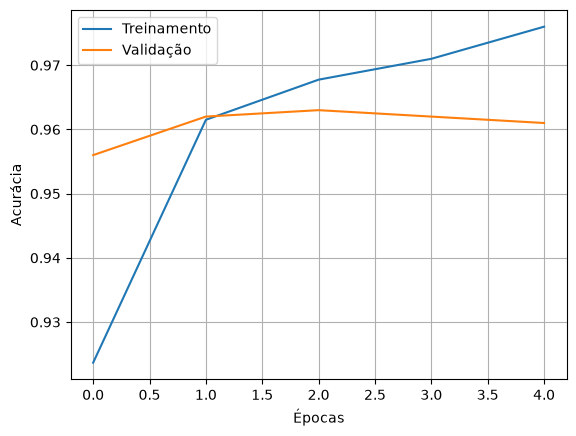

In [10]:
plt.plot(history.history['accuracy'], label='Treinamento')
plt.plot(history.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid()
plt.show()

##Avaliar o modelo

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test)

print(f'Acurácia no teste: {test_acc:.4f}')

94/94 ━━━━━━━━━━━━━━━━━━━━ 22s 231ms/step - accuracy: 0.9683 - loss: 0.0938
Acurácia no teste: 0.9683


# Fluxo de trabalho típico de Fine Tuning

Após o modelo atingir a convergência com as camadas congeladas, você pode realizar um ajuste fino (fine-tuning) descongelando todo ou parte do modelo base para treiná-lo novamente de ponta a ponta. Essa etapa opcional pode gerar melhorias incrementais, mas exige cautela para evitar o sobreajuste (overfitting) rápido.

Para que o processo funcione sem prejudicar o modelo, siga duas regras essenciais:

* **Aguarde a convergência inicial:** Nunca misture camadas recém-inicializadas com camadas pré-treinadas descongeladas desde o início, pois os gradientes altos destruiriam o aprendizado prévio.
* **Use uma taxa de aprendizado baixa:** Como o modelo inteiro será treinado em um conjunto de dados geralmente pequeno, atualizações grandes causariam sobreajuste imediato; o objetivo aqui é apenas readaptar os pesos aos poucos.

##1 - Descongelar parte da rede pré-treinada
Primeiro, descongelamos a rede e definimos quais camadas poderão ser treinadas.


Uma observação importante: na MobileNetV2, há camadas BatchNormalization. É recomendável mantê-las congeladas durante o Fine-Tuning, especialmente quando o conjunto de dados é pequeno, para evitar alterações indesejadas nas estatísticas previamente aprendidas.


In [11]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

 #Verificar quantidade de camadas treináveis
print("Camadas totais:", len(base_model.layers))
print("Camadas treináveis:",
      sum(layer.trainable for layer in base_model.layers))

Camadas totais: 154
Camadas treináveis: 19


##2 - Recompilar o modelo

Depois de modificar quais camadas são treináveis, precisamos recompilar o modelo.

Tipicamente utilizamos uma taxa de aprendizado menor, pois não queremos modificar drasticamente os pesos que já foram aprendidos.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

## 3 - Continuar o treinamento


In [ ]:
history_fine = model.fit(x_train, y_train, epochs=5, batch_size=32, validation_split=0.2)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 170s 438ms/step - accuracy: 0.9801 - loss: 0.0580 - val_accuracy: 0.9687 - val_loss: 0.0929
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 146s 389ms/step - accuracy: 0.9920 - loss: 0.0285 - val_accuracy: 0.9670 - val_loss: 0.0977
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 197s 376ms/step - accuracy: 0.9967 - loss: 0.0146 - val_accuracy: 0.9663 - val_loss: 0.0994
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 140s 373ms/step - accuracy: 0.9992 - loss: 0.0075 - val_accuracy: 0.9697 - val_loss: 0.0984
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 139s 371ms/step - accuracy: 0.9997 - loss: 0.0047 - val_accuracy: 0.9700 - val_loss: 0.1016


## 4- Comparar os resultados

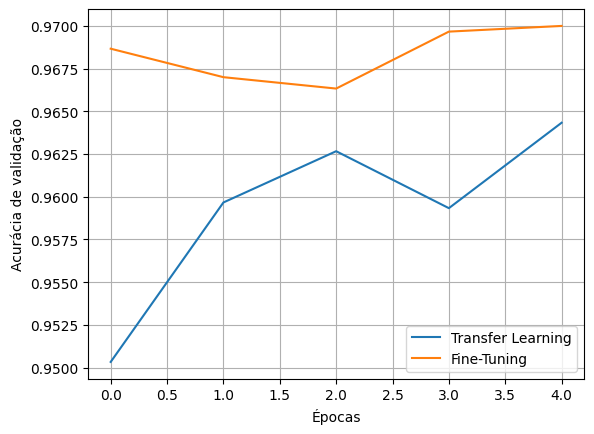

In [ ]:
plt.plot(history.history['val_accuracy'], label='Transfer Learning')

plt.plot(history_fine.history['val_accuracy'], label='Fine-Tuning')

plt.xlabel('Épocas')
plt.ylabel('Acurácia de validação')
plt.legend()
plt.grid()
plt.show()